# ML 04 - Customer Segmentation: RFM + K-Means / Hierarchical Clustering

**Objective:** segment the customers of a UK-based online wholesaler by purchasing behaviour (Recency, Frequency, Monetary value), choose the number of segments with objective criteria, validate that the segmentation is stable and **meaningful for the future**, and describe each segment in business terms.

**Dataset:** UCI *Online Retail II* (1,067,371 transaction lines, 01-Dec-2009 to 09-Dec-2011; public download, no login). The file is 45 MB, so it is **not stored in the repository** - the notebook downloads it automatically from the UCI archive (or reads a local copy).

**Methods:** K-Means (k = 2..10) with elbow / silhouette / Calinski-Harabasz / Davies-Bouldin, bootstrap stability (ARI), Ward hierarchical clustering as a cross-check, and a forward-looking validation (segments built on past data vs. what customers spent afterwards).

In [1]:
import warnings, os, io, zipfile, urllib.request
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
sns.set_theme(style="whitegrid")
OUT = Path("."); SEED = 42
CACHE = Path(os.environ.get("RETAIL_CACHE_DIR", "data")); CACHE.mkdir(parents=True, exist_ok=True)
URL = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
CSV = CACHE / "online_retail_II.csv.gz"

if not CSV.exists():
    XLSX = CACHE / "online_retail_II.xlsx"
    if not XLSX.exists():
        ZIP = CACHE / "online_retail_ii.zip"
        if not ZIP.exists():
            print("Downloading", URL)
            req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
            ZIP.write_bytes(urllib.request.urlopen(req, timeout=300).read())
        with zipfile.ZipFile(ZIP) as z: z.extract("online_retail_II.xlsx", CACHE)
    sheets = pd.read_excel(XLSX, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw.to_csv(CSV, index=False)
raw = pd.read_csv(CSV, dtype={"Invoice": str, "StockCode": str}, parse_dates=["InvoiceDate"])
print(raw.shape, "| period:", raw.InvoiceDate.min(), "->", raw.InvoiceDate.max())
raw.head(3)

(1067371, 8) | period: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom


## 1. Cleaning (every step counts rows removed)
Standard transaction-data hygiene: customers without ID cannot be profiled; cancellations (invoice starting with `C`) and non-positive quantity/price lines are not purchases; non-product stock codes (postage, fees, adjustments) would distort monetary value; exact duplicates are dropped.

In [2]:
log = [("raw lines", len(raw))]
df = raw.copy()
df = df[df["Customer ID"].notna()]; log.append(("with Customer ID", len(df)))
df["Customer ID"] = df["Customer ID"].astype(int)
cancel = df[df.Invoice.str.startswith("C")]
df = df[~df.Invoice.str.startswith("C")]; log.append(("excluding cancellations", len(df)))
df = df[(df.Quantity > 0) & (df.Price > 0)]; log.append(("Quantity>0 & Price>0", len(df)))
non_prod = df.StockCode.str.upper().str.match(r"^(POST|D|M|DOT|BANK CHARGES|AMAZONFEE|ADJUST\d*|TEST\d*|S|B|CRUK|C2|PADS|GIFT.*)$")
print("non-product lines:", int(non_prod.sum()), "| examples:", df.loc[non_prod, "StockCode"].value_counts().head(8).to_dict())
df = df[~non_prod]; log.append(("excluding non-product codes", len(df)))
df = df.drop_duplicates(); log.append(("dropping exact duplicates", len(df)))
df["Revenue"] = df.Quantity * df.Price
print(pd.DataFrame(log, columns=["step", "rows"]).assign(removed=lambda t: -t.rows.diff().fillna(0).astype(int)).to_string(index=False))
print("\nCustomers:", df["Customer ID"].nunique(), "| invoices:", df.Invoice.nunique(), "| countries:", df.Country.nunique(), "| UK share of revenue: %.1f%%" % (100 * df.loc[df.Country == "United Kingdom", "Revenue"].sum() / df.Revenue.sum()))
print("Cancelled lines excluded from the base RFM (kept aside):", len(cancel))

non-product lines: 2915 | examples: {'POST': 1838, 'M': 709, 'C2': 253, 'BANK CHARGES': 32, 'ADJUST': 32, 'PADS': 17, 'DOT': 16, 'TEST001': 9}


                       step    rows  removed
                  raw lines 1067371        0
           with Customer ID  824364   243007
    excluding cancellations  805620    18744
       Quantity>0 & Price>0  805549       71
excluding non-product codes  802634     2915
  dropping exact duplicates  776579    26055

Customers: 5852 | invoices: 36594 | countries: 41 | UK share of revenue: 83.7%
Cancelled lines excluded from the base RFM (kept aside): 18744


## 2. RFM features
Snapshot date = day after the last transaction. **Recency** = days since last purchase; **Frequency** = number of distinct invoices; **Monetary** = total revenue (GBP). All three are right-skewed, so they are log-transformed (`log1p`) and standardised before clustering - otherwise a handful of huge wholesale accounts would define the clusters.

Snapshot:

 2011-12-10 | customers: 5852


,Recency,Frequency,Monetary
count,5852.0,5852.0,5852.0
mean,199.7,6.3,2916.7
std,208.5,12.7,14306.9
min,0.0,1.0,3.0
25%,25.0,1.0,339.6
50%,95.0,3.0,856.0
75%,379.0,7.0,2241.0
95%,623.0,20.0,9270.3
max,738.0,373.0,580987.0


Skewness raw: {'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33}
Skewness log1p: {'Recency': -0.55, 'Frequency': 1.0, 'Monetary': 0.27}


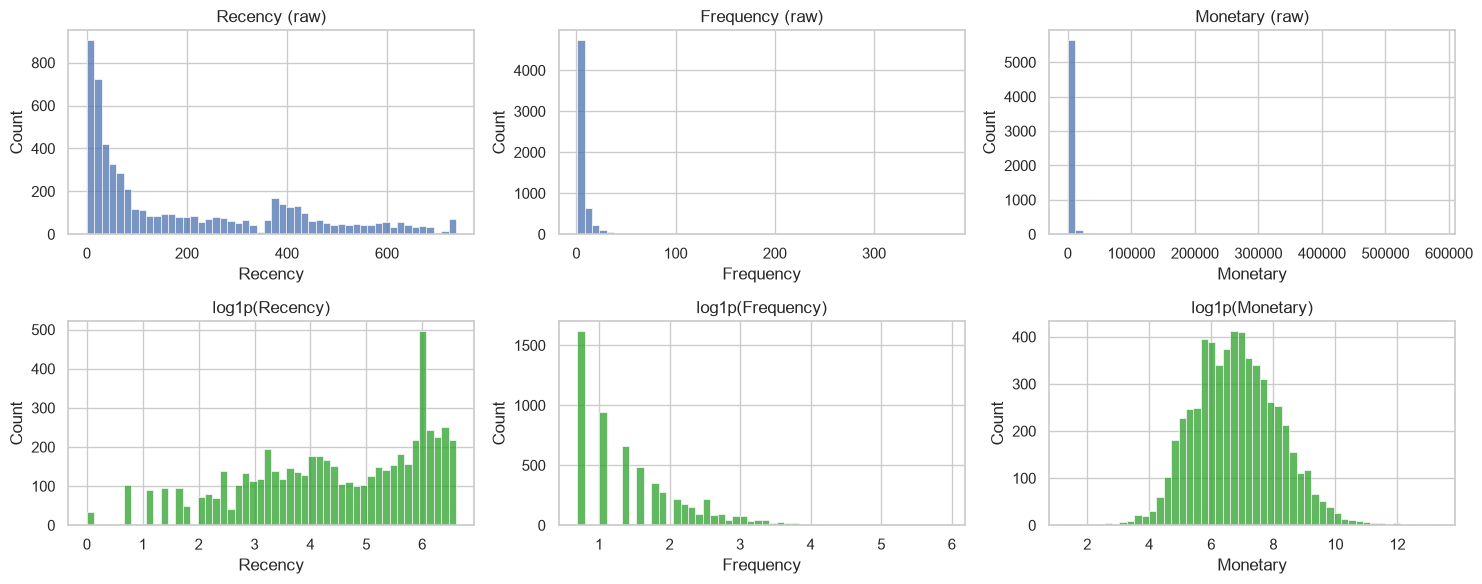

In [3]:
def rfm(frame, snapshot):
    g = frame.groupby("Customer ID")
    t = pd.DataFrame({"Recency": (snapshot - g.InvoiceDate.max()).dt.days, "Frequency": g.Invoice.nunique(), "Monetary": g.Revenue.sum()})
    return t[t.Monetary > 0]
SNAP = df.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
R = rfm(df, SNAP)
print("Snapshot:", SNAP.date(), "| customers:", len(R))
display(R.describe(percentiles=[.25, .5, .75, .95]).round(1))
print("Skewness raw:", R.skew().round(2).to_dict())
L = np.log1p(R); print("Skewness log1p:", L.skew().round(2).to_dict())
sc = StandardScaler().fit(L); X = sc.transform(L)
fig, ax = plt.subplots(2, 3, figsize=(15, 6))
for j, c in enumerate(R.columns):
    sns.histplot(R[c], bins=50, ax=ax[0, j]); ax[0, j].set_title(f"{c} (raw)")
    sns.histplot(L[c], bins=50, ax=ax[1, j], color="tab:green"); ax[1, j].set_title(f"log1p({c})")
plt.tight_layout(); plt.savefig(OUT / "01_rfm_distributions.png", dpi=130); plt.show()

## 3. Choosing k
K-Means for k = 2..10 (20 initialisations each). Criteria: inertia (elbow), mean silhouette, Calinski-Harabasz (higher = better), Davies-Bouldin (lower = better). Silhouette is computed on all customers.

,inertia,silhouette,calinski_harabasz,davies_bouldin,min_cluster_size
k,,,,,
2,8572.636,0.439,6130.299,0.874,2300
3,6358.499,0.347,5150.159,1.035,1183
4,4948.336,0.365,4966.647,0.940,1110
5,4128.117,0.341,4754.780,0.958,463
6,3578.145,0.336,4567.475,0.960,443
7,3204.687,0.304,4362.678,0.978,334
8,2915.023,0.305,4193.268,0.974,326
9,2673.992,0.291,4064.923,1.005,256
10,2482.948,0.289,3940.539,1.012,218


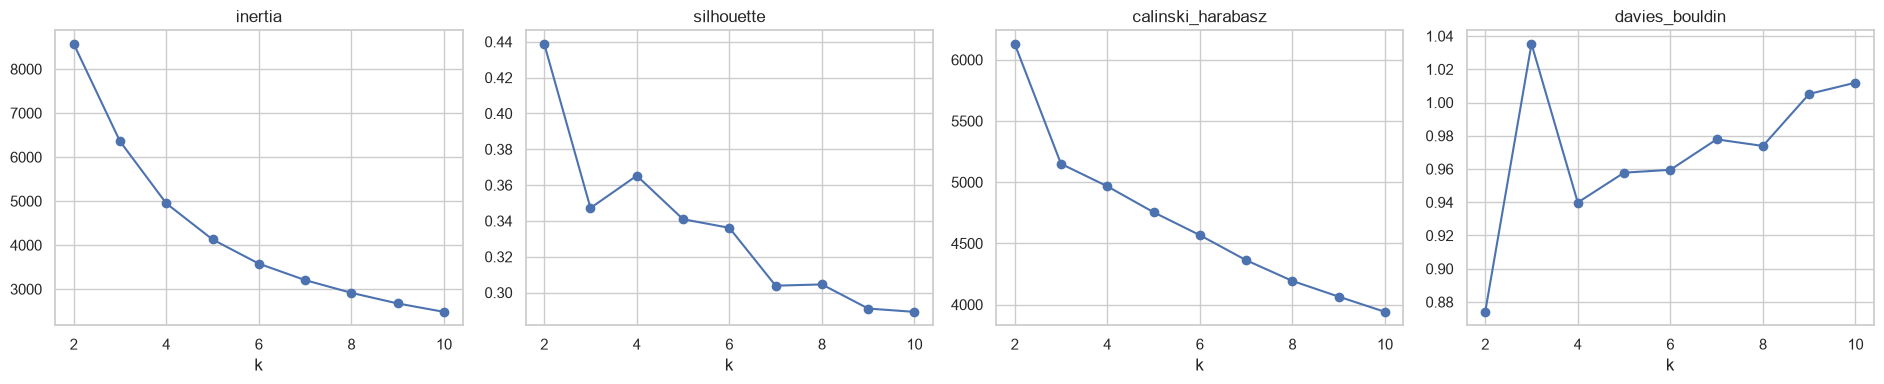

In [4]:
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=20, random_state=SEED).fit(X)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X, km.labels_), "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                 "davies_bouldin": davies_bouldin_score(X, km.labels_), "min_cluster_size": np.bincount(km.labels_).min()})
sel = pd.DataFrame(rows).set_index("k")
display(sel.round(3)); sel.round(4).to_csv(OUT / "cluster_selection_metrics.csv")
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for a, c in zip(ax, ["inertia", "silhouette", "calinski_harabasz", "davies_bouldin"]):
    sel[c].plot(ax=a, marker="o"); a.set_title(c); a.set_xlabel("k")
plt.tight_layout(); plt.savefig(OUT / "02_choose_k.png", dpi=130); plt.show()

### Stability (bootstrap ARI)
For each k, K-Means is refit on 30 bootstrap resamples and the resulting partitions are compared with the full-data partition on the customers of the resample (Adjusted Rand Index; 1 = identical). A good k combines a decent silhouette with high stability and a business-usable number of segments.

In [5]:
rng = np.random.default_rng(SEED)
full = {k: KMeans(k, n_init=20, random_state=SEED).fit(X) for k in range(2, 9)}
stab = {}
for k in range(2, 9):
    aris = []
    for b in range(30):
        idx = rng.choice(len(X), len(X), replace=True)
        kb = KMeans(k, n_init=5, random_state=b).fit(X[idx])
        aris.append(adjusted_rand_score(full[k].labels_[idx], kb.labels_))   # same rows: bootstrap partition vs full-data partition
    stab[k] = (np.mean(aris), np.std(aris))
stab = pd.DataFrame(stab, index=["ARI mean", "ARI std"]).T
sel2 = sel.loc[2:8, ["silhouette", "davies_bouldin"]].join(stab)
display(sel2.round(3)); sel2.round(4).to_csv(OUT / "cluster_stability.csv")

,silhouette,davies_bouldin,ARI mean,ARI std
k,,,,
2,0.439,0.874,0.975,0.016
3,0.347,1.035,0.943,0.032
4,0.365,0.940,0.916,0.037
5,0.341,0.958,0.901,0.067
6,0.336,0.960,0.840,0.089
7,0.304,0.978,0.781,0.143
8,0.305,0.974,0.728,0.105


### Decision: k = 4
- **k = 2** has the best silhouette (0.439) and the highest stability (ARI 0.975), but it only separates "active" from "lapsed" customers - no actionable differentiation among the valuable ones.
- Among k >= 3, **k = 4 is the local optimum**: silhouette rises from 0.347 (k=3) to 0.365 and then falls (0.341 at k=5, 0.336 at k=6); Davies-Bouldin is also better at k=4 (0.940) than at k=3 or k=5; the partition stays stable (bootstrap ARI 0.92) and every segment is large (smallest = 1,110 customers). From k = 5 the smallest cluster shrinks below 500 and stability drops (ARI <= 0.90, rising variance).
- The elbow in inertia is gradual (no sharp kink), so it supports the choice only weakly; the decision rests on silhouette / Davies-Bouldin / stability and on being able to name and act on four segments.

In [6]:
K = int(os.environ.get("K_FINAL", "0")) or 4
print("Chosen k =", K)
km = full[K] if K in full else KMeans(K, n_init=20, random_state=SEED).fit(X)
R["cluster"] = km.labels_

Chosen k = 4


## 4. Cross-check with hierarchical (Ward) clustering
Ward linkage on the same standardised features. Agreement with K-Means is measured with ARI, and the silhouette of both partitions is compared.

K-Means silhouette: 0.365 | Ward silhouette: 0.290 | ARI(KMeans, Ward): 0.529


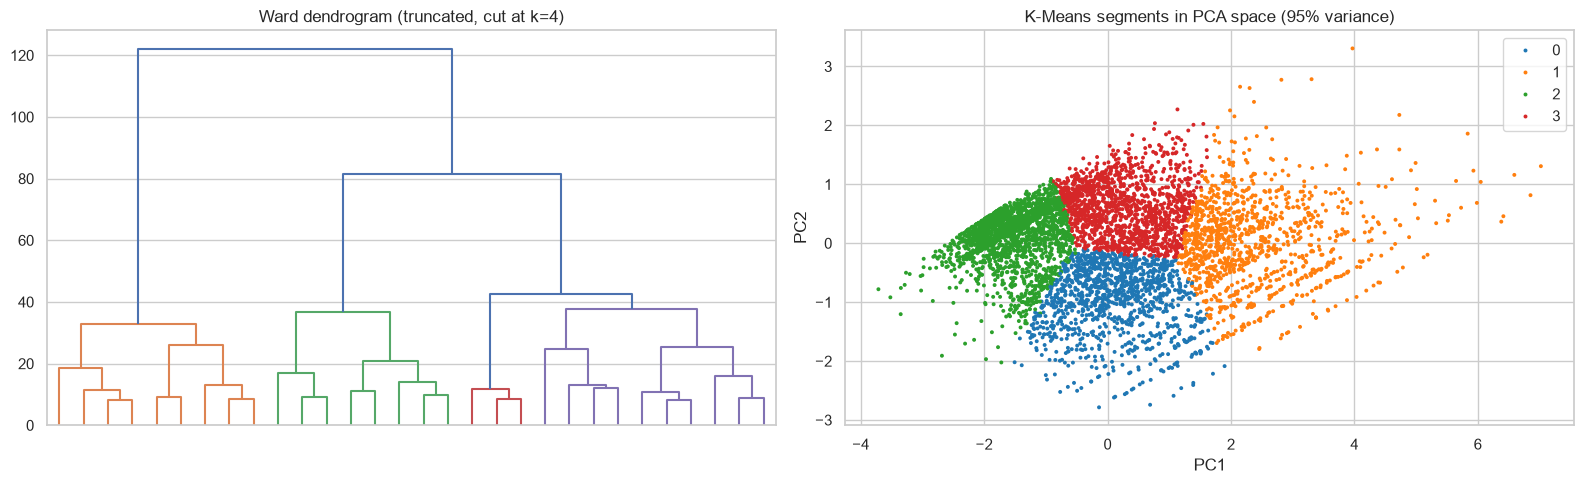

In [7]:
Zl = linkage(X, method="ward")
hc = fcluster(Zl, K, criterion="maxclust") - 1
print("K-Means silhouette: %.3f | Ward silhouette: %.3f | ARI(KMeans, Ward): %.3f" % (silhouette_score(X, km.labels_), silhouette_score(X, hc), adjusted_rand_score(km.labels_, hc)))
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
dendrogram(Zl, truncate_mode="lastp", p=30, ax=ax[0], no_labels=True, color_threshold=Zl[-(K - 1), 2]); ax[0].set_title(f"Ward dendrogram (truncated, cut at k={K})")
pca = PCA(2, random_state=SEED).fit(X); P = pca.transform(X)
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=km.labels_, palette="tab10", s=8, ax=ax[1], linewidth=0)
ax[1].set_title("K-Means segments in PCA space (%.0f%% variance)" % (100 * pca.explained_variance_ratio_.sum())); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.savefig(OUT / "03_dendrogram_pca.png", dpi=130); plt.show()

## 5. Segment profiles in business terms
Segment names are assigned by rule from the centroids relative to the overall median (recent vs. lapsed, frequent vs. rare, high vs. low value) so the labels follow the data rather than being imposed.

,customers,recency_median,frequency_median,monetary_median,revenue,monetary_mean,share_customers_%,share_revenue_%,segment
cluster,,,,,,,,,
1,1110,15.0,13.0,5117.7,12217512.2,11006.8,19.0,71.6,Champions
3,1468,157.0,5.0,1580.4,3150628.2,2146.2,25.1,18.5,At risk (formerly big)
0,1220,23.0,3.0,707.7,1002636.2,821.8,20.8,5.9,Recent / occasional
2,2054,398.0,1.0,291.4,697806.2,339.7,35.1,4.1,Lapsed / low value


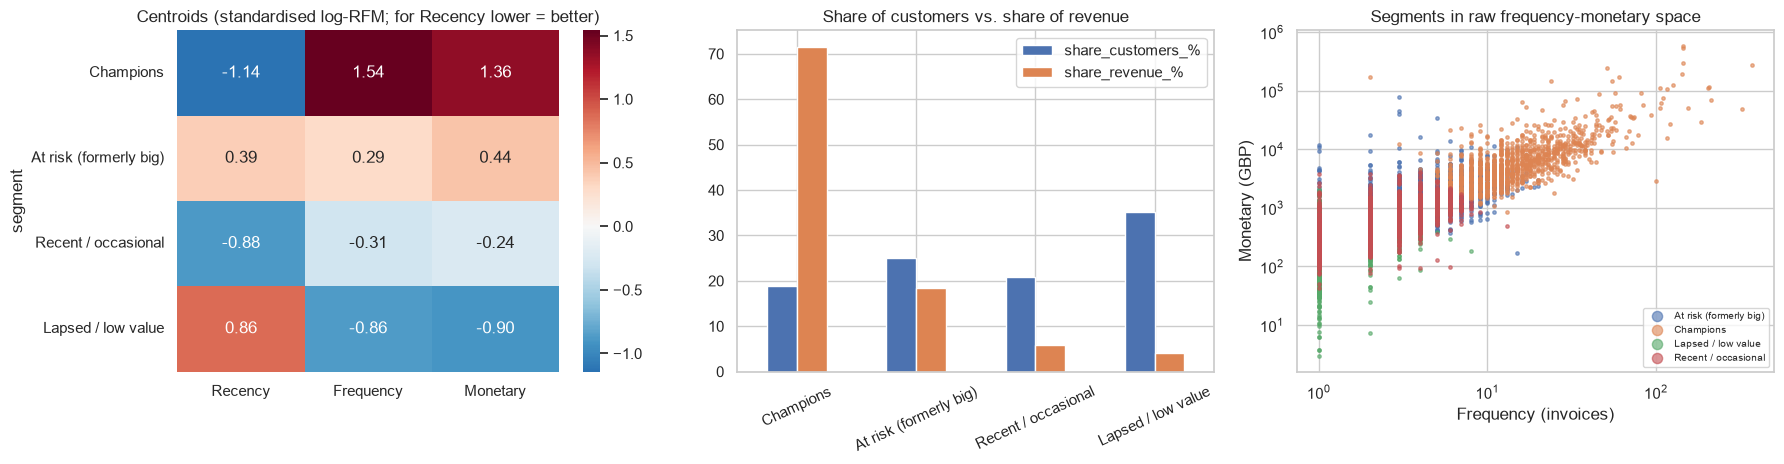

In [8]:
prof = R.groupby("cluster").agg(customers=("Recency", "size"), recency_median=("Recency", "median"), frequency_median=("Frequency", "median"),
                                monetary_median=("Monetary", "median"), revenue=("Monetary", "sum"), monetary_mean=("Monetary", "mean"))
prof["share_customers_%"] = 100 * prof.customers / prof.customers.sum()
prof["share_revenue_%"] = 100 * prof.revenue / prof.revenue.sum()
med = R[["Recency", "Frequency", "Monetary"]].median()
def label(r, med):
    rec_good = r.recency_median < med.Recency; freq_hi = r.frequency_median > med.Frequency; val_hi = r.monetary_median > med.Monetary
    if rec_good and freq_hi and val_hi: return "Champions"
    if rec_good and freq_hi: return "Loyal regulars"
    if rec_good: return "Recent / occasional"
    if freq_hi and val_hi: return "At risk (formerly big)"
    if freq_hi: return "At risk"
    return "Lapsed / low value"
def dedupe(t):
    dup = t.segment.duplicated(keep=False)
    t.loc[dup, "segment"] = t.loc[dup].apply(lambda r: f"{r.segment} (#{r.name})", axis=1)
    return t
prof["segment"] = prof.apply(lambda r: label(r, med), axis=1); prof = dedupe(prof)
prof = prof.sort_values("revenue", ascending=False)
display(prof.round(1))
R["segment"] = R.cluster.map(prof.segment)
prof.round(2).to_csv(OUT / "segment_profile.csv")
R.reset_index().to_csv(OUT / "customer_segments.csv", index=False)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
z = pd.DataFrame(X, columns=["Recency", "Frequency", "Monetary"], index=R.index).groupby(R.segment).mean().loc[prof.segment]
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Centroids (standardised log-RFM; for Recency lower = better)")
prof.set_index("segment")[["share_customers_%", "share_revenue_%"]].plot.bar(ax=ax[1]); ax[1].set_title("Share of customers vs. share of revenue"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=25)
for s_, g in R.groupby("segment"): ax[2].scatter(g.Frequency, g.Monetary, s=6, label=s_, alpha=.6)
ax[2].set_xscale("log"); ax[2].set_yscale("log"); ax[2].set_xlabel("Frequency (invoices)"); ax[2].set_ylabel("Monetary (GBP)"); ax[2].legend(fontsize=7, markerscale=3); ax[2].set_title("Segments in raw frequency-monetary space")
plt.tight_layout(); plt.savefig(OUT / "04_segment_profiles.png", dpi=130); plt.show()

## 6. Forward-looking validation
A segmentation is only useful if it says something about **future** behaviour. I rebuild RFM using only transactions **before 9-Jun-2011**, fit K-Means (same k, scaler fitted on that period only), and compare what each segment spent in the following six months (9-Jun-2011 to 9-Dec-2011). Customers who did not buy again count as zero spend.

Customers in past window: 4941 | active in the next 6 months: 52.1%


,customers,recency_median,frequency_median,past_monetary_median,repurchase_rate,future_spend_mean,future_spend_total,share_future_revenue_%,share_customers_%,segment
cluster,,,,,,,,,,
3,726,20.0,13.0,5213.27,0.93,4116.83,2988815.41,65.57,14.69,Champions
1,654,19.0,3.0,902.66,0.70,562.07,367594.82,8.06,13.24,Recent / occasional
0,1505,176.0,4.0,1333.70,0.57,515.76,776220.43,17.03,30.46,At risk (formerly big)
2,2056,239.0,1.0,286.12,0.28,206.99,425566.00,9.34,41.61,Lapsed / low value


R^2 of log(1+future spend) explained by segment dummies: 0.300 | by raw log-RFM: 0.357 | by log-Recency alone: 0.226


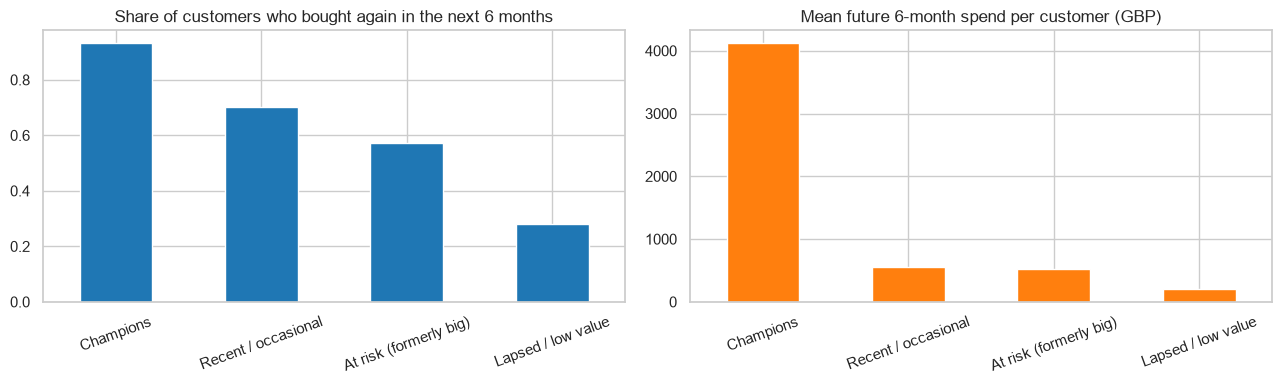

In [9]:
CUT = pd.Timestamp("2011-06-09")
past, fut = df[df.InvoiceDate < CUT], df[df.InvoiceDate >= CUT]
Rp = rfm(past, CUT); Lp = np.log1p(Rp); Xp = StandardScaler().fit_transform(Lp)
kmp = KMeans(K, n_init=20, random_state=SEED).fit(Xp); Rp["cluster"] = kmp.labels_
Rp["future_spend"] = fut.groupby("Customer ID").Revenue.sum().reindex(Rp.index).fillna(0)
Rp["returned"] = (Rp.future_spend > 0).astype(int)
vp = Rp.groupby("cluster").agg(customers=("Recency", "size"), recency_median=("Recency", "median"), frequency_median=("Frequency", "median"),
                               past_monetary_median=("Monetary", "median"), repurchase_rate=("returned", "mean"),
                               future_spend_mean=("future_spend", "mean"), future_spend_total=("future_spend", "sum"))
vp["share_future_revenue_%"] = 100 * vp.future_spend_total / vp.future_spend_total.sum()
vp["share_customers_%"] = 100 * vp.customers / vp.customers.sum()
medp = Rp[["Recency", "Frequency", "Monetary"]].median()
vp["segment"] = vp.assign(monetary_median=vp.past_monetary_median).apply(lambda r: label(r, medp), axis=1); vp = dedupe(vp)
vp = vp.sort_values("future_spend_mean", ascending=False)
print("Customers in past window:", len(Rp), "| active in the next 6 months: %.1f%%" % (100 * Rp.returned.mean()))
display(vp.round(2)); vp.round(3).to_csv(OUT / "forward_validation_segments.csv")
# how much of the future-spend variance (log) do the segments explain, vs a plain Recency-only rule?
from sklearn.linear_model import LinearRegression
y_log = np.log1p(Rp.future_spend.values)
def r2(Xm): return LinearRegression().fit(Xm, y_log).score(Xm, y_log)
seg_dummies = pd.get_dummies(Rp.cluster).values.astype(float)
print("R^2 of log(1+future spend) explained by segment dummies: %.3f | by raw log-RFM: %.3f | by log-Recency alone: %.3f" % (r2(seg_dummies), r2(Xp), r2(Xp[:, [0]])))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
vp.set_index("segment")["repurchase_rate"].plot.bar(ax=ax[0], color="tab:blue"); ax[0].set_title("Share of customers who bought again in the next 6 months"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=20)
vp.set_index("segment")["future_spend_mean"].plot.bar(ax=ax[1], color="tab:orange"); ax[1].set_title("Mean future 6-month spend per customer (GBP)"); ax[1].set_xlabel(""); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig(OUT / "05_forward_validation.png", dpi=130); plt.show()

## 7. Conclusions and limitations

**Data and cleaning:** 1,067,371 transaction lines -> 776,579 after cleaning (22.8% of lines had no Customer ID, 18,744 were cancellations, 2,915 non-product codes, 26,055 exact duplicates) -> **5,852 customers**, 36,594 invoices; 83.7% of revenue is UK.

**Choice of k:** silhouette 0.439 (k=2), 0.347 (3), **0.365 (4)**, 0.341 (5), 0.336 (6); Davies-Bouldin best at k=2 (0.87) then k=4 (0.94); bootstrap ARI 0.975 / 0.943 / **0.916** / 0.901 / 0.840 for k = 2..6. k=2 is the statistically best but only separates active from lapsed; k=4 is the best-supported richer solution (every cluster has >= 1,110 customers, stable). The elbow is gradual and supports the choice only weakly.

**Segments (K-Means, k=4, full history)**

| Segment | Customers | Share of revenue | Median recency (days) | Median frequency (invoices) | Median spend (GBP) |
|---|---|---|---|---|---|
| Champions | 1,110 (19.0%) | **71.6%** | 15 | 13 | 5,118 |
| At risk (formerly big) | 1,468 (25.1%) | 18.5% | 157 | 5 | 1,580 |
| Recent / occasional | 1,220 (20.8%) | 5.9% | 23 | 3 | 708 |
| Lapsed / low value | 2,054 (35.1%) | 4.1% | 398 | 1 | 291 |

1. **Revenue is highly concentrated:** one fifth of customers (Champions) bring 72% of revenue; the 35% of customers who bought once long ago bring 4%. Priorities: protect Champions (service level, stock availability of their usual items), reactivate the large "At risk" group (25% of customers, still 18.5% of revenue, 157 days of silence), convert "Recent / occasional" buyers to a second and third order.
2. **Forward validation (the segmentation predicts the future).** Re-fitting on data before 9-Jun-2011 and following the 4,941 customers for six months: Champions (14.7% of customers) repurchase 93% of the time, spend GBP 4,117 on average and generate **65.6% of future revenue**; Recent/occasional 70% / GBP 562; At-risk 57% / GBP 516; Lapsed 28% / GBP 207. The ordering is monotonic on both measures. Segment membership explains R2 = 0.30 of log future spend (raw log-RFM 0.36, recency alone 0.23; in-sample linear fits, descriptive only).
3. **Hierarchical cross-check:** Ward clustering at k=4 has a lower silhouette (0.290 vs 0.365) and only moderate agreement with K-Means (ARI 0.53), i.e. the structure is a continuum with soft boundaries rather than four well-separated groups; K-Means was kept as the better-fitting partition.

**Limitations**
- RFM describes *how much and how recently* customers buy, not *what* they buy; no product-mix, margin or return behaviour is used (cancellations are excluded from monetary value, so heavy returners look better than they are).
- 22.8% of lines have no Customer ID (probably guest/one-off buyers) and are not segmented, so segment revenue shares are shares of *identified* revenue.
- Silhouette values (0.29-0.44) indicate overlapping clusters; segment boundaries are not natural gaps. Names are assigned by a rule on centroids, not discovered.
- Exact duplicate lines were removed (3.2% of rows); some may be genuine repeated scans of the same item, which would understate monetary value slightly.
- One retailer, two years, a UK-centric B2B/B2C mix (gift-ware); the 2009-11 period includes a strong Q4 seasonality that affects recency. The forward test uses a single cut-off date.